# Function to automatic merge and fill missing values



## Create the function
You have to create a function which take 2 arguments :
- argument 1 : DataFrame main
- argument 2 : DataFrame opinion

Your function will return a new DataFrame which is the left merge of both DataFrames, and which has no missing values (so your function has to fill them), add new columns (flag, MONTH and DAY), and OPINION should be translated.

So you have to copy each useful code from the previous quests, and integrate it into a function. **This should achieve the same results as the previous quests.**

In [1]:
import pandas as pd

In [2]:
# Chargement des Datasets

link_main = "https://raw.githubusercontent.com/murpi/wilddata/master/quests/weather_main_2018.csv"
link_opinion = "https://raw.githubusercontent.com/murpi/wilddata/master/quests/weather_opinion_2018.csv"
df_main = pd.read_csv(link_main)
df_opinion = pd.read_csv(link_opinion)


In [3]:
# Affichage des premières lignes de df_main
df_main.head()


,DATE,MAX_TEMPERATURE_C,MIN_TEMPERATURE_C,WINDSPEED_MAX_KMH,TEMPERATURE_MORNING_C,TEMPERATURE_NOON_C,TEMPERATURE_EVENING_C,PRECIP_TOTAL_DAY_MM,HUMIDITY_MAX_PERCENT,VISIBILITY_AVG_KM,PRESSURE_MAX_MB,CLOUDCOVER_AVG_PERCENT,HEATINDEX_MAX_C,DEWPOINT_MAX_C,WINDTEMP_MAX_C
0,2018-01-01,12,8,61,9,11,8,8.9,79,9.500,1018,41.750,12,8,7
1,2018-01-02,13,6,26,8,12,13,0.6,96,9.000,1020,87.875,13,12,6
2,2018-01-03,15,10,40,11,12,10,5.5,82,8.500,1017,91.500,15,13,7
3,2018-01-04,14,11,45,14,14,11,0.0,89,10.000,1011,90.125,14,12,10
4,2018-01-05,12,7,21,10,11,8,1.5,85,9.875,1005,62.375,12,10,7


In [4]:
# Affichage des premières lignes de df_opinion
df_opinion.head()

,date,WEATHER_CODE_EVENING,TOTAL_SNOW_MM,UV_INDEX,SUNHOUR,OPINION
0,2018-01-01,113,0,3,5.1,bad
1,2018-03-12,119,0,2,8.8,bad
2,2018-03-09,116,0,3,10.2,bad
3,2018-10-07,122,0,1,5.6,bad
4,2018-06-18,119,0,1,12.9,bad


In [5]:
# Affichage du nombre de lignes et de colonnes de df_main
df_main.shape

(365, 15)

In [6]:
# Affichage des informations de df_main
df_main.info()

<class 'pandas.DataFrame'>
RangeIndex: 365 entries, 0 to 364
Data columns (total 15 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   DATE                    365 non-null    str    
 1   MAX_TEMPERATURE_C       365 non-null    int64  
 2   MIN_TEMPERATURE_C       365 non-null    int64  
 3   WINDSPEED_MAX_KMH       365 non-null    int64  
 4   TEMPERATURE_MORNING_C   365 non-null    int64  
 5   TEMPERATURE_NOON_C      365 non-null    int64  
 6   TEMPERATURE_EVENING_C   365 non-null    int64  
 7   PRECIP_TOTAL_DAY_MM     365 non-null    float64
 8   HUMIDITY_MAX_PERCENT    365 non-null    int64  
 9   VISIBILITY_AVG_KM       365 non-null    float64
 10  PRESSURE_MAX_MB         365 non-null    int64  
 11  CLOUDCOVER_AVG_PERCENT  365 non-null    float64
 12  HEATINDEX_MAX_C         365 non-null    int64  
 13  DEWPOINT_MAX_C          365 non-null    int64  
 14  WINDTEMP_MAX_C          365 non-null    int64  
dtype

In [7]:
# Nombre de valeurs nulles de df_main
df_main.isna().sum()

DATE                      0
MAX_TEMPERATURE_C         0
MIN_TEMPERATURE_C         0
WINDSPEED_MAX_KMH         0
TEMPERATURE_MORNING_C     0
TEMPERATURE_NOON_C        0
TEMPERATURE_EVENING_C     0
PRECIP_TOTAL_DAY_MM       0
HUMIDITY_MAX_PERCENT      0
VISIBILITY_AVG_KM         0
PRESSURE_MAX_MB           0
CLOUDCOVER_AVG_PERCENT    0
HEATINDEX_MAX_C           0
DEWPOINT_MAX_C            0
WINDTEMP_MAX_C            0
dtype: int64

In [8]:
# Nombre de lignes et de colonnes de df_opinion
df_opinion.shape

(341, 6)

In [9]:
# Nombre de valeurs nulles de df_opinion
df_opinion.isna().sum()

date                    0
WEATHER_CODE_EVENING    0
TOTAL_SNOW_MM           0
UV_INDEX                0
SUNHOUR                 0
OPINION                 0
dtype: int64

In [10]:
# Création d'une fonction merge_and_fill qui prend en paramètre
# deux DataFrame pour les joindre avec un left join sur la colonne de date

from datetime import datetime

def traduire_opinion(opinion):
  traductions = {
      "very bad": "très mauvais",
      "bad": "mauvais",
      "not good not bad": "ni bon ni mauvais",
      "good": "bon",
      "very good": "très bon",
      "Unknown": "inconnu",
      "météo très défavorable": "très mauvais",
      "météo défavorable": "mauvais",
      "météo correcte": "ni bon ni mauvais",
      "météo favorable": "bon",
      "météo idéale": "très bon",
  }
  return traductions.get(opinion, opinion)

def merge_and_fill(DataFrameMain, DataFrameOpinion):
  # MERGE BOTH DATAFRAMES
  NewDataFrame = pd.merge(DataFrameMain, DataFrameOpinion, how="left", left_on="DATE", right_on="date")
  NewDataFrame = NewDataFrame.drop(columns="date")

  # FILL IN MISSING VALUES
  # WEATHER_CODE_EVENING => mode
  NewDataFrame["WEATHER_CODE_EVENING"] = NewDataFrame["WEATHER_CODE_EVENING"].fillna(NewDataFrame["WEATHER_CODE_EVENING"].mode()[0])

  # TOTAL_SNOW_MM => moyenne
  NewDataFrame["TOTAL_SNOW_MM"] = NewDataFrame["TOTAL_SNOW_MM"].fillna(NewDataFrame["TOTAL_SNOW_MM"].mean())

  # UV_INDEX => médiane
  NewDataFrame["UV_INDEX"] = NewDataFrame["UV_INDEX"].fillna(NewDataFrame["UV_INDEX"].median())

  # SUNHOUR => bfill
  NewDataFrame["SUNHOUR"] = NewDataFrame["SUNHOUR"].bfill()

  # OPINION => remplacer les nuls par "Unknown"
  NewDataFrame["OPINION"] = NewDataFrame["OPINION"].fillna("Unknown")

  # Ajout de la colonne FLAG pour OPINION nulles
  NewDataFrame["FLAG"] = NewDataFrame["OPINION"] == "Unknown"

  # Conversion de la colonne DATE au format Datetime
  NewDataFrame["DATE"] = pd.to_datetime(NewDataFrame["DATE"])

  # Création de la colonne MONTH
  NewDataFrame["MONTH"] = NewDataFrame["DATE"].dt.strftime("%m")

  # Création de la colonne DAY
  NewDataFrame["DAY"] = NewDataFrame["DATE"].dt.strftime("%d")

  # Tradudction de la colonne OPINION en français (créer une fonction)
  NewDataFrame["OPINION"] = NewDataFrame["OPINION"].apply(traduire_opinion)

  # Return new merged dataframe
  return NewDataFrame

In [11]:
df_2018 = merge_and_fill(df_main, df_opinion)

In [12]:
# Afficher le nombre de lignes et de colonnes de df_2018
# Afficher les premières ignes de df_2018
print(df_2018.shape)
df_2018.head()

(365, 23)


,DATE,MAX_TEMPERATURE_C,MIN_TEMPERATURE_C,WINDSPEED_MAX_KMH,TEMPERATURE_MORNING_C,TEMPERATURE_NOON_C,TEMPERATURE_EVENING_C,PRECIP_TOTAL_DAY_MM,HUMIDITY_MAX_PERCENT,VISIBILITY_AVG_KM,...,DEWPOINT_MAX_C,WINDTEMP_MAX_C,WEATHER_CODE_EVENING,TOTAL_SNOW_MM,UV_INDEX,SUNHOUR,OPINION,FLAG,MONTH,DAY
0,2018-01-01,12,8,61,9,11,8,8.9,79,9.500,...,8,7,113.0,0.0,3.0,5.1,mauvais,False,01,01
1,2018-01-02,13,6,26,8,12,13,0.6,96,9.000,...,12,6,122.0,0.0,3.0,3.3,mauvais,False,01,02
2,2018-01-03,15,10,40,11,12,10,5.5,82,8.500,...,13,7,122.0,0.0,3.0,3.3,mauvais,False,01,03
3,2018-01-04,14,11,45,14,14,11,0.0,89,10.000,...,12,10,116.0,0.0,3.0,3.3,mauvais,False,01,04
4,2018-01-05,12,7,21,10,11,8,1.5,85,9.875,...,10,7,116.0,0.0,3.0,6.9,mauvais,False,01,05


In [13]:
# Afficher les informations de df_2018
df_2018.info()

<class 'pandas.DataFrame'>
RangeIndex: 365 entries, 0 to 364
Data columns (total 23 columns):
 #   Column                  Non-Null Count  Dtype         
---  ------                  --------------  -----         
 0   DATE                    365 non-null    datetime64[us]
 1   MAX_TEMPERATURE_C       365 non-null    int64         
 2   MIN_TEMPERATURE_C       365 non-null    int64         
 3   WINDSPEED_MAX_KMH       365 non-null    int64         
 4   TEMPERATURE_MORNING_C   365 non-null    int64         
 5   TEMPERATURE_NOON_C      365 non-null    int64         
 6   TEMPERATURE_EVENING_C   365 non-null    int64         
 7   PRECIP_TOTAL_DAY_MM     365 non-null    float64       
 8   HUMIDITY_MAX_PERCENT    365 non-null    int64         
 9   VISIBILITY_AVG_KM       365 non-null    float64       
 10  PRESSURE_MAX_MB         365 non-null    int64         
 11  CLOUDCOVER_AVG_PERCENT  365 non-null    float64       
 12  HEATINDEX_MAX_C         365 non-null    int64         
 13  D

## Execution with a loop
You will execute your function in a 9 rounds loop, once per year, and agregate this in a new big DataFrame with 24 columns and lots of rows.

In [14]:
# Chaque année entre 2010 et 2018 (inclus) a deux 2 sources : weather_main_YYYY.csv and weather_opinion_YYYY.csv
# Charger les deux datasets et joingez-les grâce à la fonction merge_and_fill
# Concaténez ce nouveau DataFrame au(x) précédent(s) pour n'obtenir qu'un long DataFrame df_weather

df_weather = pd.DataFrame()

# Créez la boucle :
annees = []
for year in range(2010, 2019):
    main = pd.read_csv(f"https://raw.githubusercontent.com/murpi/wilddata/master/quests/weather_main_{year}.csv")
    opinion = pd.read_csv(f"https://raw.githubusercontent.com/murpi/wilddata/master/quests/weather_opinion_{year}.csv")
    annees.append(merge_and_fill(main, opinion))

df_weather = pd.concat(annees, ignore_index=True)
df_weather.shape

(3287, 23)

In [15]:
# Affichage des premières lignes de df_weather
df_weather.head()

,DATE,MAX_TEMPERATURE_C,MIN_TEMPERATURE_C,WINDSPEED_MAX_KMH,TEMPERATURE_MORNING_C,TEMPERATURE_NOON_C,TEMPERATURE_EVENING_C,PRECIP_TOTAL_DAY_MM,HUMIDITY_MAX_PERCENT,VISIBILITY_AVG_KM,...,DEWPOINT_MAX_C,WINDTEMP_MAX_C,WEATHER_CODE_EVENING,TOTAL_SNOW_MM,UV_INDEX,SUNHOUR,OPINION,FLAG,MONTH,DAY
0,2010-01-01,5,2,19,2,5,3,0.0,86,10.000,...,3,-1,119.0,0.0,1.0,5.1,très mauvais,False,01,01
1,2010-01-02,5,-1,6,-1,4,1,0.0,78,10.000,...,0,2,116.0,0.0,1.0,8.7,très mauvais,False,01,02
2,2010-01-03,5,1,26,2,4,2,0.3,61,9.875,...,0,-3,119.0,0.0,1.0,6.9,très mauvais,False,01,03
3,2010-01-04,1,-4,25,-2,0,-3,0.0,75,10.000,...,0,-9,113.0,0.0,1.0,8.7,très mauvais,False,01,04
4,2010-01-05,2,-5,20,-5,1,-4,0.0,71,10.000,...,0,-10,113.0,0.0,1.0,8.7,très mauvais,False,01,05


In [16]:
# Création d'une fonction clean qui :
# * crée une colonne FLAG indiquant une valeur manquante
# * convertit la colonne DATE au format datetime
# * traduit l'opinion en français

def clean(DataFrameYear):

  # ALIGN DATAFRAME SHAPE, DATATYPE
  colonnes = [col for col in df_weather.columns if col in DataFrameYear.columns]
  DataFrameYear = DataFrameYear[colonnes].copy()

  # Colonne FLAG
  DataFrameYear["FLAG"] = DataFrameYear.isna().any(axis=1)

  # Colone DATE
  DataFrameYear["DATE"] = pd.to_datetime(DataFrameYear["DATE"])
  DataFrameYear["MONTH"] = DataFrameYear["DATE"].dt.strftime("%m")
  DataFrameYear["DAY"] = DataFrameYear["DATE"].dt.strftime("%d")

  # Colonne OPINION
  DataFrameYear["OPINION"] = DataFrameYear["OPINION"].apply(traduire_opinion)

  # Return new cleaned dataframe
  return DataFrameYear[df_weather.columns]

In [17]:
# On crée une liste de DataFrames pour les années 2019 à 2022 (inclus)

links = {}
for year in range(2019, 2023):
    # Collect both DataFrames each year
    year = str(year)
    links[year] = "https://raw.githubusercontent.com/WildCodeSchool/data-training-resources/main/quests/weather" + year + ".csv"

# Create dataframes from the links to clean
dfs = {}  # Dictionary to store dataframes
for year, link in links.items():
    dfs[year] = pd.read_csv(link)
    dfs[year] = clean(dfs[year])

dfs['2019']

,DATE,MAX_TEMPERATURE_C,MIN_TEMPERATURE_C,WINDSPEED_MAX_KMH,TEMPERATURE_MORNING_C,TEMPERATURE_NOON_C,TEMPERATURE_EVENING_C,PRECIP_TOTAL_DAY_MM,HUMIDITY_MAX_PERCENT,VISIBILITY_AVG_KM,...,DEWPOINT_MAX_C,WINDTEMP_MAX_C,WEATHER_CODE_EVENING,TOTAL_SNOW_MM,UV_INDEX,SUNHOUR,OPINION,FLAG,MONTH,DAY
0,2019-01-01,9,4,10,4,7,8,0.2,94,9.000,...,6,3,176,0,1,5.1,très mauvais,False,01,01
1,2019-01-02,8,5,18,7,7,5,0.0,90,9.000,...,6,3,116,0,1,8.7,très mauvais,False,01,02
2,2019-01-03,6,0,18,0,4,3,0.0,88,10.000,...,1,-4,116,0,1,8.7,très mauvais,False,01,03
3,2019-01-04,5,-1,15,-1,4,3,0.0,91,10.000,...,1,-4,122,0,1,5.1,très mauvais,False,01,04
4,2019-01-05,6,-1,8,-1,4,3,0.0,91,8.000,...,2,-2,116,0,1,8.7,très mauvais,False,01,05
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
360,2019-12-27,13,10,13,10,12,11,0.0,96,7.375,...,10,8,116,0,1,8.7,ni bon ni mauvais,False,12,27
361,2019-12-28,11,5,12,7,8,8,0.0,93,7.625,...,9,4,116,0,1,6.9,très mauvais,False,12,28
362,2019-12-29,9,2,11,3,6,7,0.0,86,10.000,...,4,0,116,0,1,8.7,très mauvais,False,12,29
363,2019-12-30,12,4,7,5,9,9,0.0,61,10.000,...,4,4,113,0,1,8.7,très mauvais,False,12,30


In [18]:
# Concaténez df_weather avec df_2019 à 2022
df_weather = pd.concat([df_weather] + list(dfs.values()), ignore_index=True)
df_weather.shape

(4748, 23)

In [19]:
# Affichez les premières lignes de df_weather
df_weather

,DATE,MAX_TEMPERATURE_C,MIN_TEMPERATURE_C,WINDSPEED_MAX_KMH,TEMPERATURE_MORNING_C,TEMPERATURE_NOON_C,TEMPERATURE_EVENING_C,PRECIP_TOTAL_DAY_MM,HUMIDITY_MAX_PERCENT,VISIBILITY_AVG_KM,...,DEWPOINT_MAX_C,WINDTEMP_MAX_C,WEATHER_CODE_EVENING,TOTAL_SNOW_MM,UV_INDEX,SUNHOUR,OPINION,FLAG,MONTH,DAY
0,2010-01-01,5,2,19,2,5,3,0.0,86,10.000,...,3,-1,119.0,0.0,1.0,5.1,très mauvais,False,01,01
1,2010-01-02,5,-1,6,-1,4,1,0.0,78,10.000,...,0,2,116.0,0.0,1.0,8.7,très mauvais,False,01,02
2,2010-01-03,5,1,26,2,4,2,0.3,61,9.875,...,0,-3,119.0,0.0,1.0,6.9,très mauvais,False,01,03
3,2010-01-04,1,-4,25,-2,0,-3,0.0,75,10.000,...,0,-9,113.0,0.0,1.0,8.7,très mauvais,False,01,04
4,2010-01-05,2,-5,20,-5,1,-4,0.0,71,10.000,...,0,-10,113.0,0.0,1.0,8.7,très mauvais,False,01,05
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4743,2022-12-27,10,3,19,3,7,8,0.1,78,10.000,...,8,0,122.0,0.0,3.0,6.9,très mauvais,False,12,27
4744,2022-12-28,12,7,35,7,12,12,0.6,95,10.000,...,11,5,353.0,0.0,4.0,6.9,mauvais,False,12,28
4745,2022-12-29,12,8,18,10,12,9,0.6,92,10.000,...,11,8,176.0,0.0,3.0,3.3,mauvais,False,12,29
4746,2022-12-30,15,7,47,11,14,15,3.5,95,9.750,...,13,7,353.0,0.0,4.0,3.3,mauvais,False,12,30


# Draw a scatterplot
With Date on X-Axis and Max Temperature on Y-axis

The result must have 11 seasonality for the 11 summers/winters alternance.

Utilisez Seaborn ou Plotly Express selon votre préférence




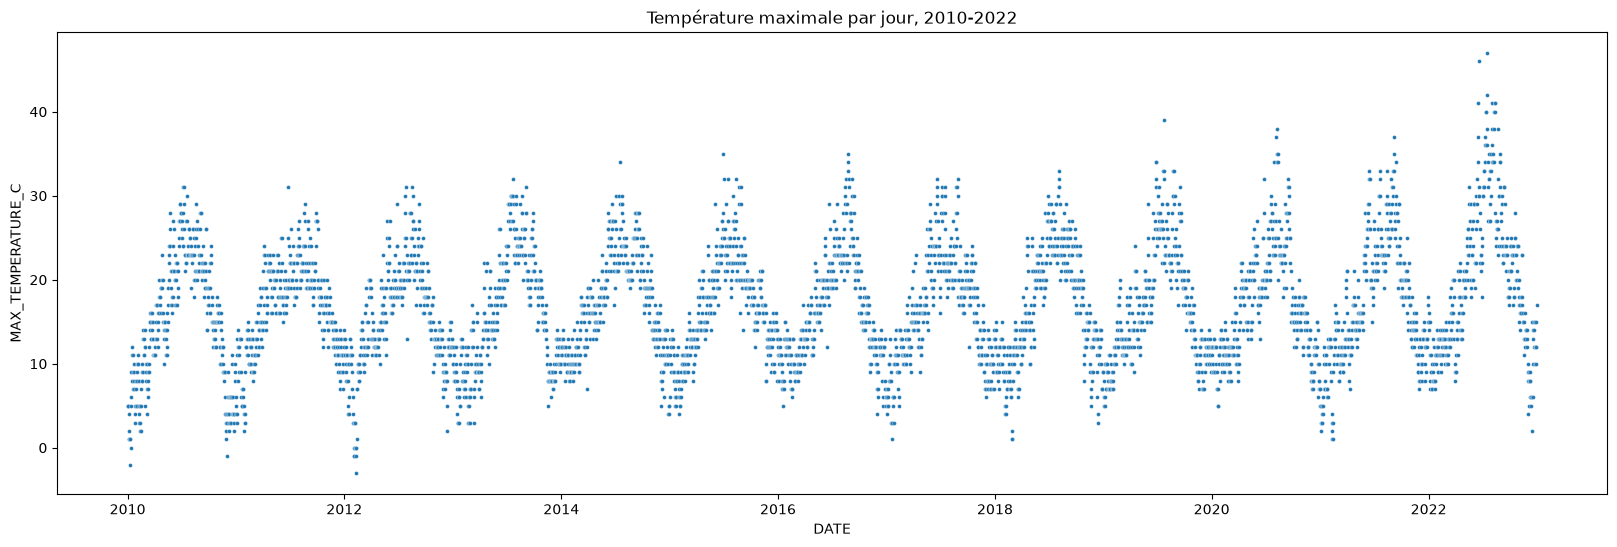

In [20]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(20, 6))
sns.scatterplot(data=df_weather, x="DATE", y="MAX_TEMPERATURE_C", s=8)
plt.title("Température maximale par jour, 2010-2022")
plt.show()


Find appropriate dataviz to answer to this question :

Which year had the best weather? Are years very different or not ?


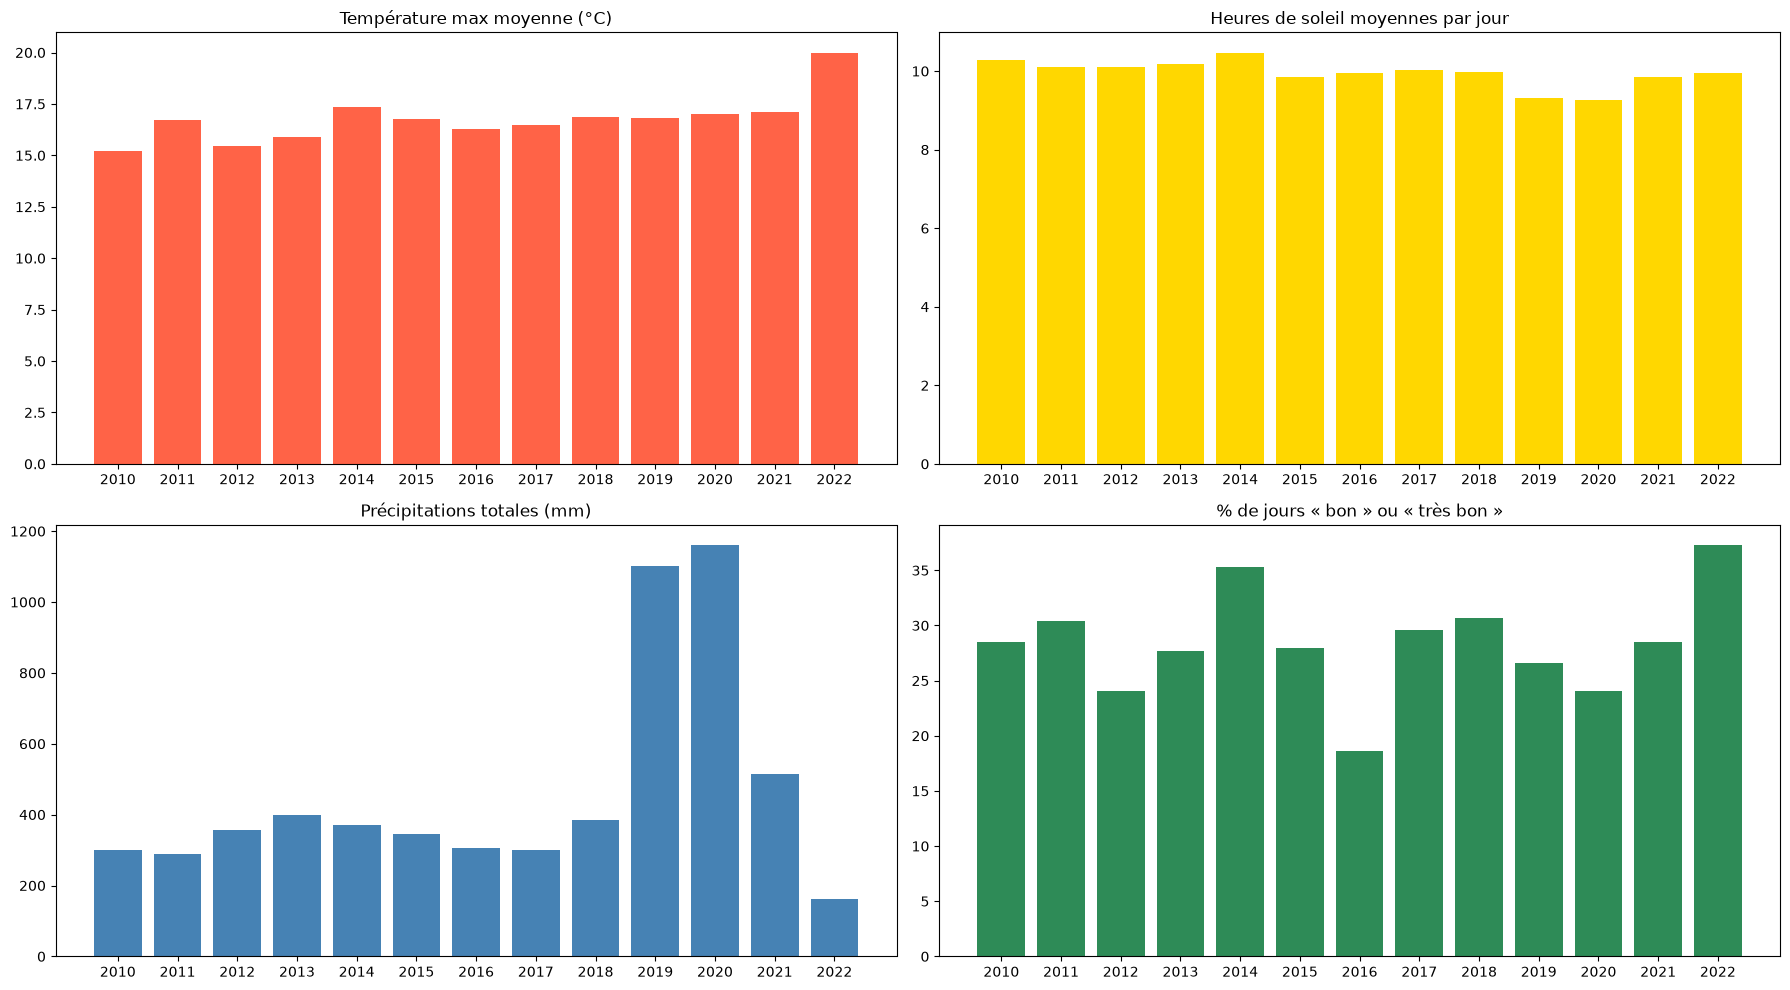

,temperature_max_moyenne,heures_soleil_moyennes,precipitations_totales,pourcentage_beaux_jours
YEAR,,,,
2010,15.2,10.3,299.1,28.5
2011,16.7,10.1,287.7,30.4
2012,15.5,10.1,357.1,24.0
2013,15.9,10.2,398.6,27.7
2014,17.4,10.5,371.7,35.3
2015,16.8,9.8,344.0,27.9
2016,16.3,9.9,306.3,18.6
2017,16.5,10.0,301.5,29.6
2018,16.9,10.0,386.1,30.7


In [21]:
df_weather["YEAR"] = df_weather["DATE"].dt.year
df_weather["BEAU_TEMPS"] = df_weather["OPINION"].isin(["bon", "très bon"])

par_annee = df_weather.groupby("YEAR").agg(
    temperature_max_moyenne=("MAX_TEMPERATURE_C", "mean"),
    heures_soleil_moyennes=("SUNHOUR", "mean"),
    precipitations_totales=("PRECIP_TOTAL_DAY_MM", "sum"),
    pourcentage_beaux_jours=("BEAU_TEMPS", "mean"),
)
par_annee["pourcentage_beaux_jours"] = par_annee["pourcentage_beaux_jours"] * 100

fig, axes = plt.subplots(2, 2, figsize=(18, 10))
titres = ["Température max moyenne (°C)", "Heures de soleil moyennes par jour",
          "Précipitations totales (mm)", "% de jours « bon » ou « très bon »"]
couleurs = ["tomato", "gold", "steelblue", "seagreen"]
for colonne, titre, couleur, ax in zip(par_annee.columns, titres, couleurs, axes.flatten()):
    ax.bar(par_annee.index, par_annee[colonne], color=couleur)
    ax.set_title(titre)
    ax.set_xticks(par_annee.index)
plt.tight_layout()
plt.show()

par_annee.round(1)

Quelles années semblent avoir bénéficié des meilleures conditions météo ? Pour quelles raisons ?

In [22]:
print(par_annee.sort_values("pourcentage_beaux_jours", ascending=False).round(1))

      temperature_max_moyenne  heures_soleil_moyennes  precipitations_totales  \
YEAR                                                                            
2022                     20.0                    10.0                   160.6   
2014                     17.4                    10.5                   371.7   
2018                     16.9                    10.0                   386.1   
2011                     16.7                    10.1                   287.7   
2017                     16.5                    10.0                   301.5   
2010                     15.2                    10.3                   299.1   
2021                     17.1                     9.8                   514.1   
2015                     16.8                     9.8                   344.0   
2013                     15.9                    10.2                   398.6   
2019                     16.8                     9.3                  1100.8   
2012                     15.